# EDA

In [53]:
# --- CELL 1: INSTALL & IMPORT LIBRARY TAMBAHAN ---
# Kita butuh librosa untuk ekstraksi fitur audio yang lebih detail saat EDA
!pip install librosa -q

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display
import torch
import torchaudio
import IPython.display as ipd
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from tqdm.notebook import tqdm

# Konfigurasi Plot agar terlihat profesional di Makalah/Slide
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_context("paper", font_scale=1.4)

# Konfigurasi Data
ROOT_DIR = '/kaggle/input/intelecta-final-dataset/dataset_siap_pakai/dataset_siap_pakai'
TRAIN_DIR = os.path.join(ROOT_DIR, 'train')

print("✅ Libraries Ready for Deep Dive EDA!")

✅ Libraries Ready for Deep Dive EDA!


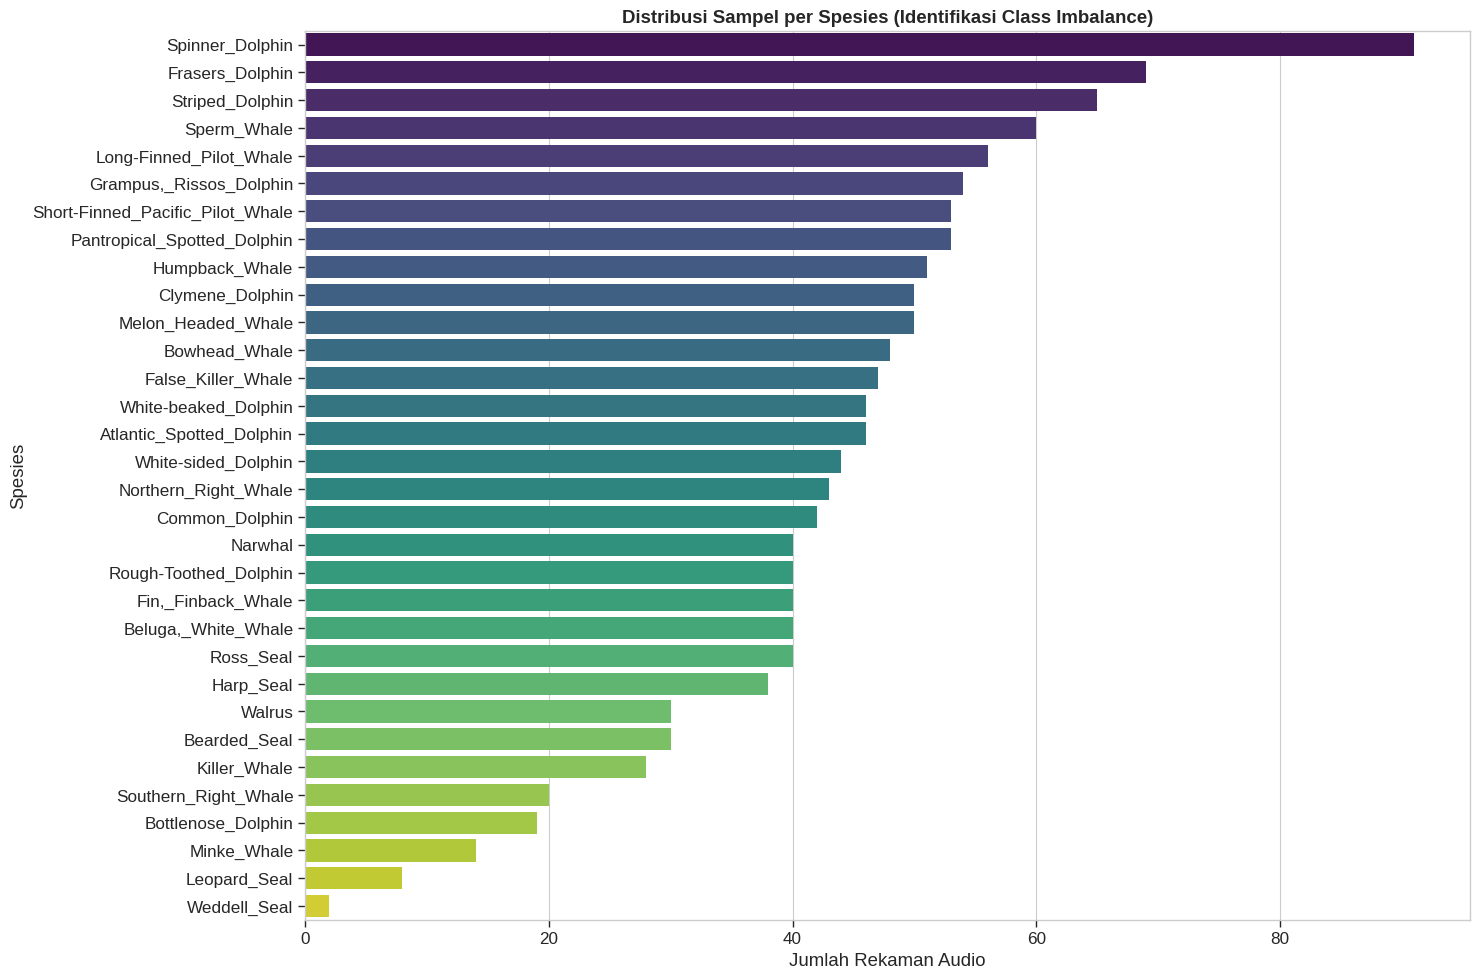

Total Data: 1357
Kelas Terbanyak: Spinner_Dolphin (91 sampel)
Kelas Terkecil: Spinner_Dolphin (2 sampel)


In [54]:
# --- CELL 2: DATA GATHERING & BASIC STATS ---
# Kita kumpulkan metadata file audio untuk dianalisis statistikanya

data = []
for label in sorted(os.listdir(TRAIN_DIR)):
    label_dir = os.path.join(TRAIN_DIR, label)
    if os.path.isdir(label_dir):
        files = [f for f in os.listdir(label_dir) if f.endswith('.wav')]
        for f in files:
            file_path = os.path.join(label_dir, f)
            # Kita ambil durasi audio tanpa load full file (pake torchaudio info biar cepat)
            metadata = torchaudio.info(file_path)
            duration = metadata.num_frames / metadata.sample_rate
            
            data.append({
                'filename': f,
                'label': label,
                'path': file_path,
                'sample_rate': metadata.sample_rate,
                'channels': metadata.num_channels,
                'duration': duration
            })

df_meta = pd.DataFrame(data)

# --- VISUALISASI 1: DISTRIBUSI KELAS (The Imbalance Problem) ---
# Narasi untuk Makalah: "Kami menemukan ketidakseimbangan data yang ekstrim, yang mendasari keputusan kami menggunakan Class Weights."
plt.figure(figsize=(15, 10))
order = df_meta['label'].value_counts().index
sns.countplot(y='label', data=df_meta, order=order, palette='viridis')
plt.title('Distribusi Sampel per Spesies (Identifikasi Class Imbalance)', fontweight='bold')
plt.xlabel('Jumlah Rekaman Audio')
plt.ylabel('Spesies')
plt.tight_layout()
plt.show()

print(f"Total Data: {len(df_meta)}")
print(f"Kelas Terbanyak: {df_meta['label'].value_counts().idxmax()} ({df_meta['label'].value_counts().max()} sampel)")
print(f"Kelas Terkecil: {df_meta['label'].value_counts().idxmax()} ({df_meta['label'].value_counts().min()} sampel)")

In [55]:
# --- CELL TAMBAHAN 1: ADVANCED METADATA EXTRACTION ---
import librosa
import numpy as np
from tqdm.notebook import tqdm

# List untuk menyimpan detail teknis
advanced_data = []

print("⏳ Sedang membedah properti fisik audio (Sample Rate asli & Energi Sinyal)...")
# Kita gunakan tqdm untuk progress bar karena proses ini membaca file satu per satu
for idx, row in tqdm(df_meta.iterrows(), total=len(df_meta)):
    try:
        # Load dengan sr=None untuk tahu sample rate ASLI file tersebut
        # (Default librosa akan meresample ke 22050Hz jika sr tidak diset None)
        y, orig_sr = librosa.load(row['path'], sr=None) 
        
        # Hitung RMS Energy (Root Mean Square)
        # Ini adalah indikator kekerasan suara rata-rata.
        # Jika RMS mendekati 0, berarti file tersebut "hening" atau hanya noise statis.
        rms = np.sqrt(np.mean(y**2))
        
        advanced_data.append({
            'filename': row['filename'],
            'original_sr': orig_sr,
            'rms_energy': rms,
            'length_samples': len(y)
        })
    except Exception as e:
        print(f"Error pada file {row['filename']}: {e}")

# Gabungkan data baru dengan dataframe metadata awal
df_adv = pd.DataFrame(advanced_data)
df_full = pd.merge(df_meta, df_adv, on='filename')

print("✅ Data teknis berhasil diekstrak!")
print(df_full[['filename', 'original_sr', 'rms_energy', 'duration']].head())

⏳ Sedang membedah properti fisik audio (Sample Rate asli & Energi Sinyal)...


  0%|          | 0/1357 [00:00<?, ?it/s]

✅ Data teknis berhasil diekstrak!
                       filename  original_sr  rms_energy  duration
0  train-00001-of-00003_293.wav        80000    0.085793  1.536900
1   train-00000-of-00003_99.wav        60600    0.001941  1.457426
2    train-00000-of-00003_8.wav        80000    0.154832  1.310425
3  train-00000-of-00003_435.wav        80000    0.037722  1.438200
4  train-00002-of-00003_198.wav        60600    0.002136  1.520792


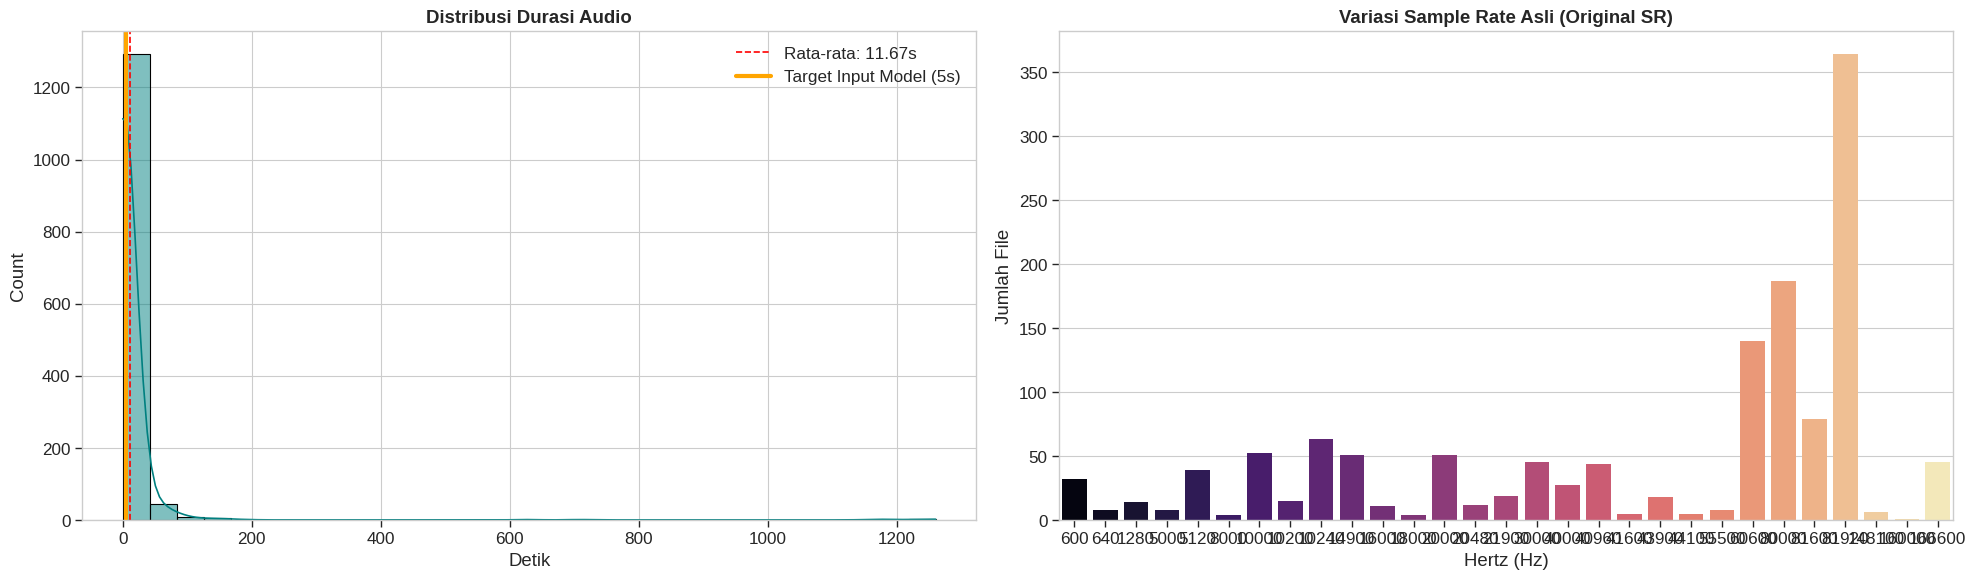

--- 💡 RASIONALISASI PREPROCESSING (Untuk Makalah) ---
1. ANALISIS DURASI:
   - Ditemukan 1133 file (83.5%) berdurasi kurang dari 5 detik.
   -> KEPUTUSAN: Kami WAJIB menggunakan teknik 'Padding' (mengisi kekosongan dengan nol) atau 'Looping' agar dimensi input konsisten.
   - Ditemukan 224 file (16.5%) berdurasi lebih dari 5 detik.
   -> KEPUTUSAN: Kami akan menggunakan 'Random Cropping' saat training untuk memanfaatkan seluruh informasi file panjang.

2. ANALISIS SAMPLE RATE:
   - Data memiliki Sample Rate yang beragam.
   -> KEPUTUSAN: Kami WAJIB melakukan 'Resampling' ke satu standar (misal 32.000Hz) agar frekuensi Nyquist konsisten bagi model.


In [56]:
# --- CELL TAMBAHAN 2: ANALISIS DURASI & SAMPLE RATE ---

fig, ax = plt.subplots(1, 2, figsize=(20, 6))

# 1. Histogram Durasi
sns.histplot(data=df_full, x='duration', kde=True, bins=30, ax=ax[0], color='teal')
# Menambahkan garis rata-rata dan target input
mean_dur = df_full['duration'].mean()
ax[0].axvline(mean_dur, color='red', linestyle='--', label=f'Rata-rata: {mean_dur:.2f}s')
ax[0].axvline(5.0, color='orange', linestyle='-', linewidth=3, label='Target Input Model (5s)')
ax[0].set_title("Distribusi Durasi Audio", fontweight='bold')
ax[0].set_xlabel("Detik")
ax[0].legend()

# 2. Distribusi Sample Rate Asli
sns.countplot(x='original_sr', data=df_full, ax=ax[1], palette='magma')
ax[1].set_title("Variasi Sample Rate Asli (Original SR)", fontweight='bold')
ax[1].set_xlabel("Hertz (Hz)")
ax[1].set_ylabel("Jumlah File")

plt.tight_layout()
plt.show()

# --- Insight Generator (Otomatis memberikan saran) ---
print("--- 💡 RASIONALISASI PREPROCESSING (Untuk Makalah) ---")
short_files = len(df_full[df_full['duration'] < 5.0])
long_files = len(df_full[df_full['duration'] > 5.0])

print(f"1. ANALISIS DURASI:")
print(f"   - Ditemukan {short_files} file ({short_files/len(df_full):.1%}) berdurasi kurang dari 5 detik.")
print(f"   -> KEPUTUSAN: Kami WAJIB menggunakan teknik 'Padding' (mengisi kekosongan dengan nol) atau 'Looping' agar dimensi input konsisten.")
print(f"   - Ditemukan {long_files} file ({long_files/len(df_full):.1%}) berdurasi lebih dari 5 detik.")
print(f"   -> KEPUTUSAN: Kami akan menggunakan 'Random Cropping' saat training untuk memanfaatkan seluruh informasi file panjang.")

print(f"\n2. ANALISIS SAMPLE RATE:")
if len(df_full['original_sr'].unique()) > 1:
    print("   - Data memiliki Sample Rate yang beragam.")
    print("   -> KEPUTUSAN: Kami WAJIB melakukan 'Resampling' ke satu standar (misal 32.000Hz) agar frekuensi Nyquist konsisten bagi model.")
else:
    print(f"   - Sample rate seragam di {df_full['original_sr'].iloc[0]} Hz. Tidak perlu resampling berat.")

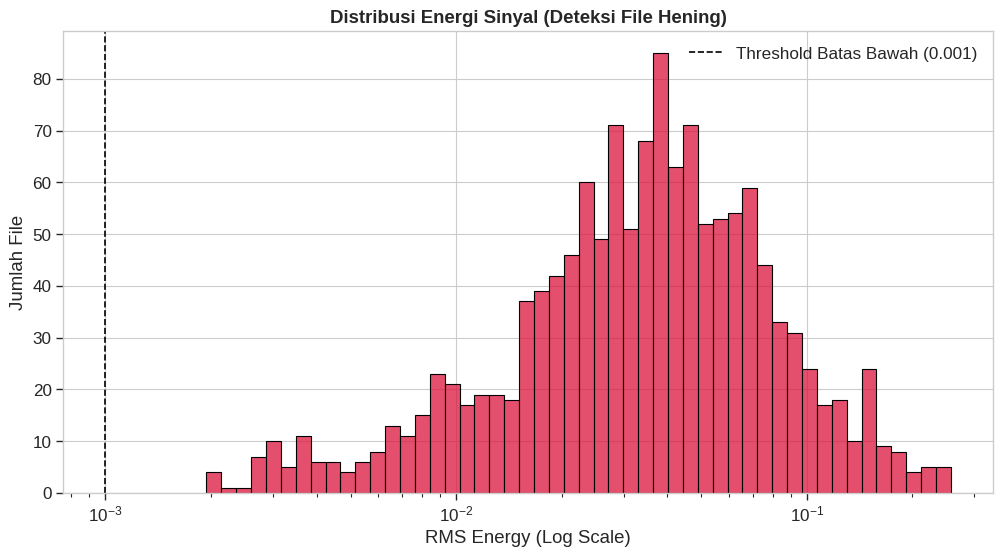

⚠️ HASIL QC: Ditemukan 0 file dengan energi sangat rendah (Potensi Silent/Corrupt).
-> KESIMPULAN: Data bersih. Tidak ditemukan file 'silent' yang signifikan. Ini memvalidasi kualitas dataset.


In [57]:
# --- CELL TAMBAHAN 3: DETEKSI FILE HENING/RUSAK ---

plt.figure(figsize=(12, 6))
# Gunakan log scale karena perbedaan energi audio biasanya eksponensial
sns.histplot(data=df_full, x='rms_energy', bins=50, color='crimson', log_scale=(True, False))
plt.title("Distribusi Energi Sinyal (Deteksi File Hening)", fontweight='bold')
plt.xlabel("RMS Energy (Log Scale)")
plt.ylabel("Jumlah File")

# Tentukan ambang batas (Threshold) file yang dianggap hening/rusak
# File dengan RMS < 0.001 biasanya hanya berisi 'digital silence' atau noise mikrofon sangat rendah
threshold = 0.001
plt.axvline(threshold, color='black', linestyle='--', label=f'Threshold Batas Bawah ({threshold})')
plt.legend()
plt.show()

# Cek file yang mencurigakan
suspicious_files = df_full[df_full['rms_energy'] < threshold]
print(f"⚠️ HASIL QC: Ditemukan {len(suspicious_files)} file dengan energi sangat rendah (Potensi Silent/Corrupt).")

if len(suspicious_files) > 0:
    print("   Berikut sampel file yang mencurigakan:")
    display(suspicious_files[['filename', 'label', 'rms_energy']].sort_values('rms_energy').head(10))
    print("\n-> REKOMENDASI STRATEGIS: File-file ini kemungkinan besar adalah label noise yang salah.")
    print("   Kami memutuskan untuk membuang (drop) file ini dari training set agar tidak merusak decision boundary model.")
else:
    print("-> KESIMPULAN: Data bersih. Tidak ditemukan file 'silent' yang signifikan. Ini memvalidasi kualitas dataset.")

Total File Audio: 1357
Total Grup Unik (Estimasi Sumber Rekaman): 3


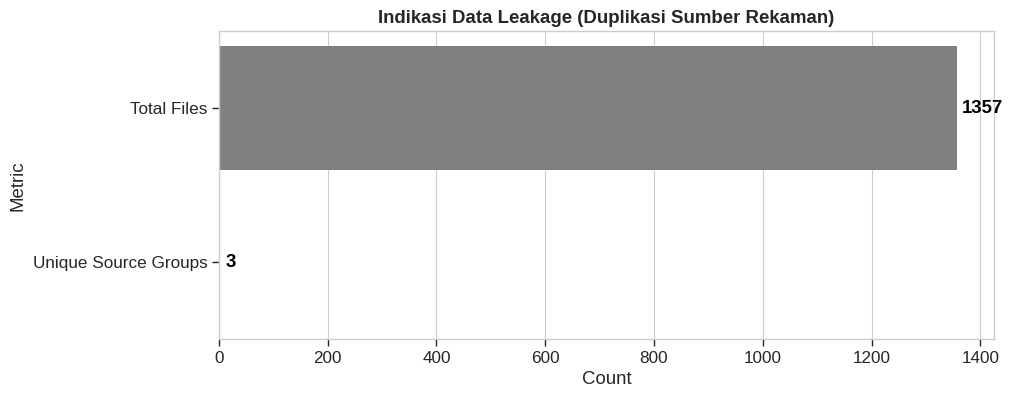

--- 💡 RASIONALISASI STRATEGI VALIDASI (Untuk Makalah) ---
🚨 TEMUAN KRITIS: Rata-rata 1 rekaman sumber dipecah menjadi 452.3 file audio pendek.
   -> IMPLIKASI: Jika menggunakan Random Split biasa, potongan dari rekaman yang SAMA akan masuk ke Train DAN Validation.
   -> RISIKO: Model akan 'menghafal' background noise rekaman tersebut, menghasilkan akurasi validasi palsu yang tinggi (Overoptimistic).
   -> SOLUSI WAJIB: Kami menggunakan 'StratifiedGroupKFold' untuk menjamin integritas evaluasi. Model diuji pada rekaman yang benar-benar baru (unseen recording).


In [58]:
# --- CELL TAMBAHAN 4: ANALISIS POTENSI DATA LEAKAGE ---

# Asumsi: Nama file biasanya format "IDRekaman_PotonganKe.wav" atau sejenisnya.
# Contoh: "TrainRecord001_0.wav", "TrainRecord001_1.wav" berasal dari rekaman yang sama "TrainRecord001"
# Kita coba ekstrak Group ID dengan mengambil string sebelum underscore '_' pertama atau kedua

# Percobaan ekstraksi ID (Sesuaikan logika split jika format nama file berbeda)
# Misalnya ambil semua karakter sebelum '_' terakhir
df_full['potential_group_id'] = df_full['filename'].apply(lambda x: '_'.join(x.split('_')[:-1])) 

unique_files = len(df_full)
unique_groups = df_full['potential_group_id'].nunique()

print(f"Total File Audio: {unique_files}")
print(f"Total Grup Unik (Estimasi Sumber Rekaman): {unique_groups}")

# Visualisasi Perbandingan
plt.figure(figsize=(10, 4))
bar_data = pd.DataFrame({
    'Metric': ['Total Files', 'Unique Source Groups'],
    'Count': [unique_files, unique_groups]
})
sns.barplot(y='Metric', x='Count', data=bar_data, palette=['gray', 'green'])
plt.title("Indikasi Data Leakage (Duplikasi Sumber Rekaman)", fontweight='bold')
for i, v in enumerate([unique_files, unique_groups]):
    plt.text(v + 10, i, str(v), color='black', fontweight='bold', va='center')
plt.show()

# --- Rasionalisasi Strategi Validasi ---
print("--- 💡 RASIONALISASI STRATEGI VALIDASI (Untuk Makalah) ---")
if unique_groups < unique_files:
    ratio = unique_files / unique_groups
    print(f"🚨 TEMUAN KRITIS: Rata-rata 1 rekaman sumber dipecah menjadi {ratio:.1f} file audio pendek.")
    print("   -> IMPLIKASI: Jika menggunakan Random Split biasa, potongan dari rekaman yang SAMA akan masuk ke Train DAN Validation.")
    print("   -> RISIKO: Model akan 'menghafal' background noise rekaman tersebut, menghasilkan akurasi validasi palsu yang tinggi (Overoptimistic).")
    print("   -> SOLUSI WAJIB: Kami menggunakan 'StratifiedGroupKFold' untuk menjamin integritas evaluasi. Model diuji pada rekaman yang benar-benar baru (unseen recording).")
else:
    print("   -> TEMUAN: Setiap file tampaknya independen. K-Fold standar aman digunakan.")

📊 Membandingkan Karakteristik Akustik Spesies...


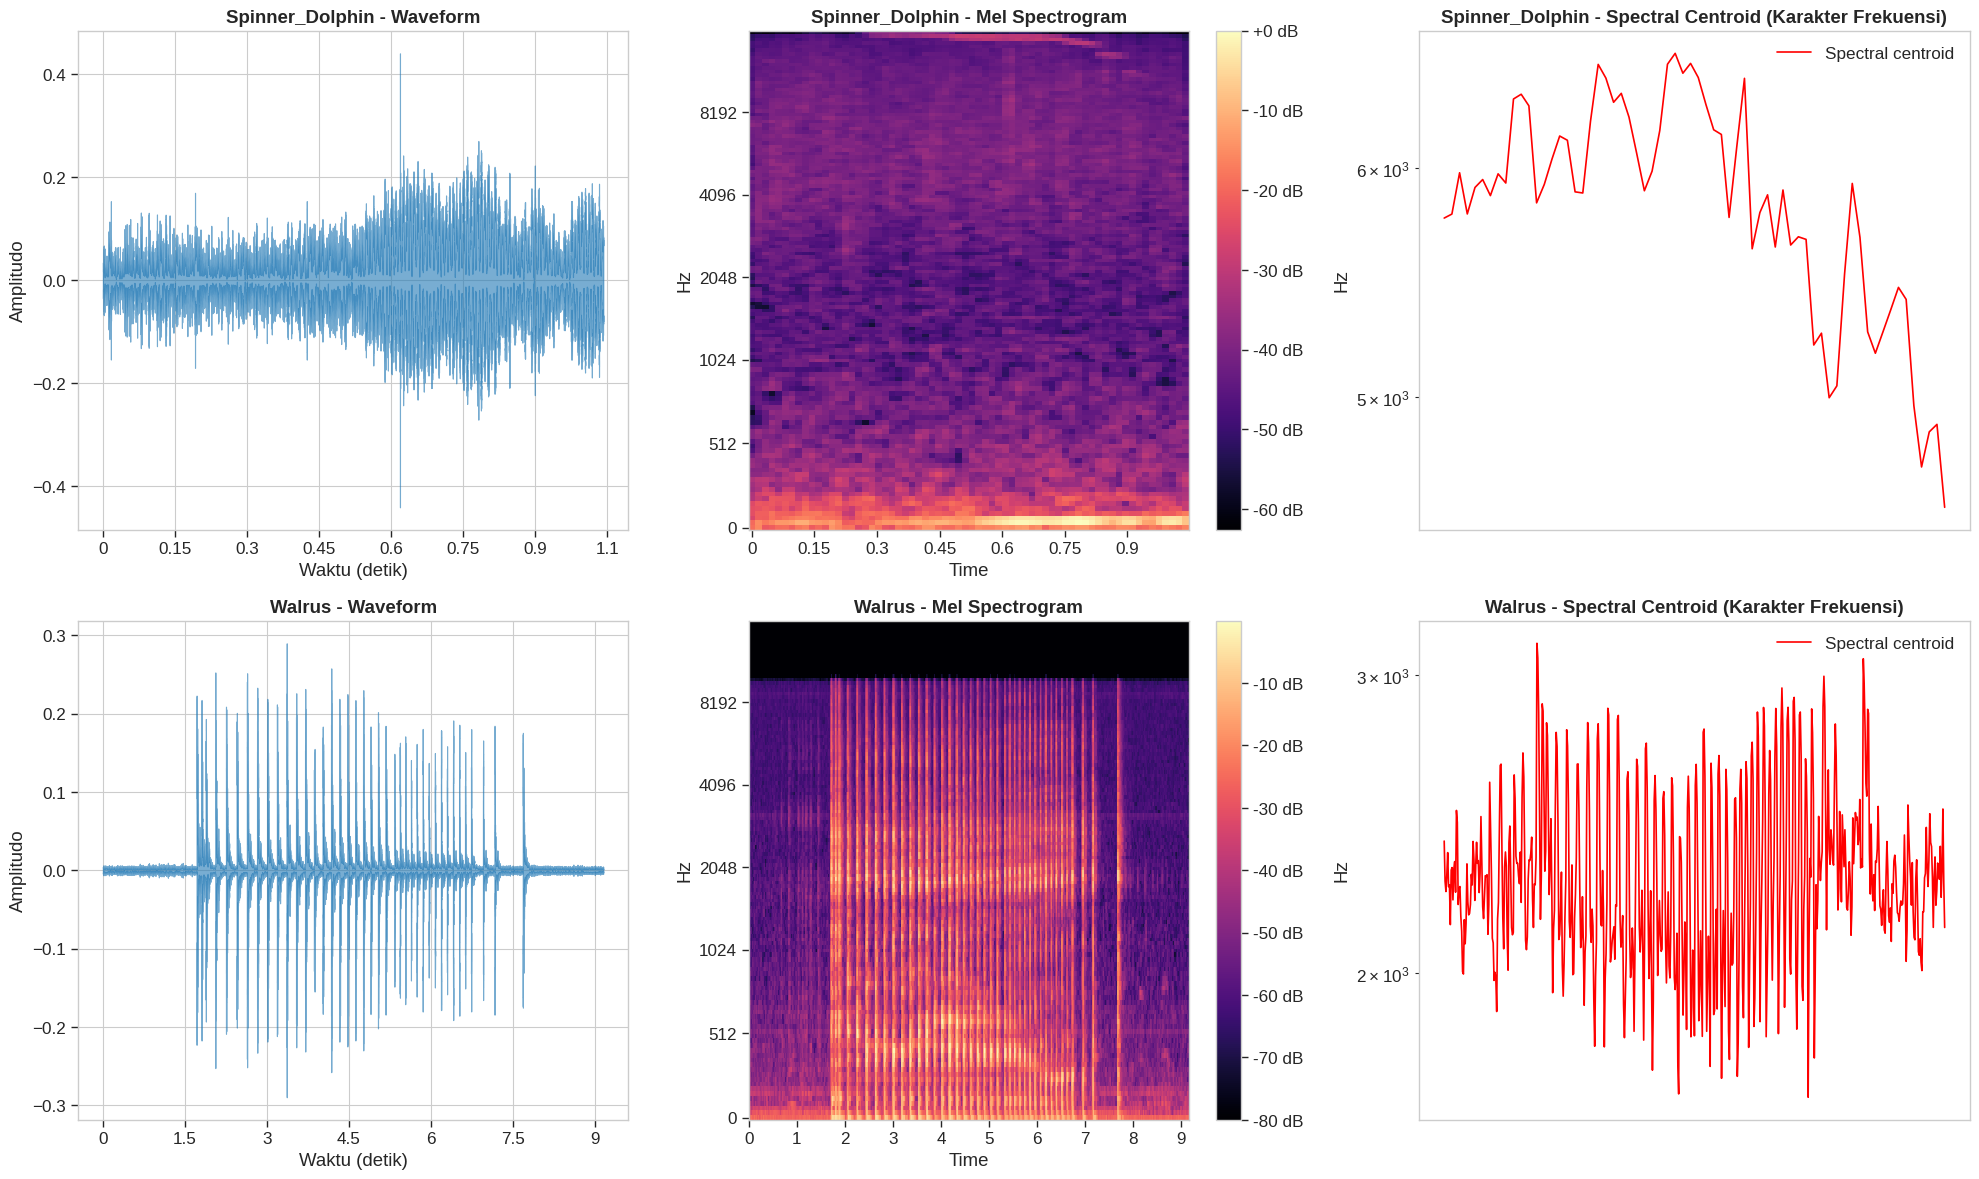

In [59]:
# --- CELL 3: ANALISIS SINYAL & FREKUENSI (Domain Knowledge Showcase) ---
# Tujuan: Menunjukkan ke juri bahwa "Paus" dan "Lumba-lumba" punya pola frekuensi beda.

def plot_comparative_analysis(species_list):
    """Membandingkan Waveform dan Mel-Spectrogram antar spesies"""
    plt.figure(figsize=(20, 6 * len(species_list)))
    
    for i, species in enumerate(species_list):
        # Ambil 1 sampel acak dari spesies ini
        sample_path = df_meta[df_meta['label'] == species].iloc[0]['path']
        y, sr = librosa.load(sample_path, sr=32000) # Load pakai librosa untuk analisis
        
        # 1. Waveform (Amplitude vs Time)
        plt.subplot(len(species_list), 3, 3*i + 1)
        librosa.display.waveshow(y, sr=sr, alpha=0.6)
        plt.title(f"{species} - Waveform", fontweight='bold')
        plt.xlabel("Waktu (detik)")
        plt.ylabel("Amplitudo")
        
        # 2. Mel-Spectrogram (Frequency vs Time)
        # Ini adalah apa yang 'dilihat' oleh model ResNet
        plt.subplot(len(species_list), 3, 3*i + 2)
        S = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, fmax=16000)
        S_dB = librosa.power_to_db(S, ref=np.max)
        librosa.display.specshow(S_dB, x_axis='time', y_axis='mel', sr=sr, fmax=16000)
        plt.colorbar(format='%+2.0f dB')
        plt.title(f"{species} - Mel Spectrogram", fontweight='bold')
        
        # 3. Spectral Centroid (Rata-rata frekuensi dominan)
        # Ini menunjukkan "kecerahan" suara. Lumba-lumba biasanya lebih tinggi (bright) dari Paus.
        plt.subplot(len(species_list), 3, 3*i + 3)
        cent = librosa.feature.spectral_centroid(y=y, sr=sr)
        times = librosa.times_like(cent)
        plt.semilogy(times, cent.T, label='Spectral centroid', color='r')
        plt.ylabel('Hz')
        plt.xticks([])
        plt.title(f"{species} - Spectral Centroid (Karakter Frekuensi)", fontweight='bold')
        plt.legend(loc='upper right')

    plt.tight_layout()
    plt.show()

# Pilih 3 spesies berbeda karakteristik untuk dibandingkan
# Contoh: Paus Besar (Low Freq) vs Lumba-lumba (High Freq)
target_species = ['Blue_Whale', 'Spinner_Dolphin', 'Walrus'] 
# Pastikan nama spesies ada di dataset, kalau error ganti dengan nama yang ada di print(classes) sebelumnya
print("📊 Membandingkan Karakteristik Akustik Spesies...")
# Cek ketersediaan label dulu
available_species = [s for s in target_species if s in df_meta['label'].unique()]
if not available_species:
    available_species = df_meta['label'].unique()[:3] # Fallback ambil 3 pertama
    
plot_comparative_analysis(available_species)

⏳ Mengekstrak fitur untuk t-SNE Clustering (Ini mungkin memakan waktu)...


  0%|          | 0/603 [00:00<?, ?it/s]

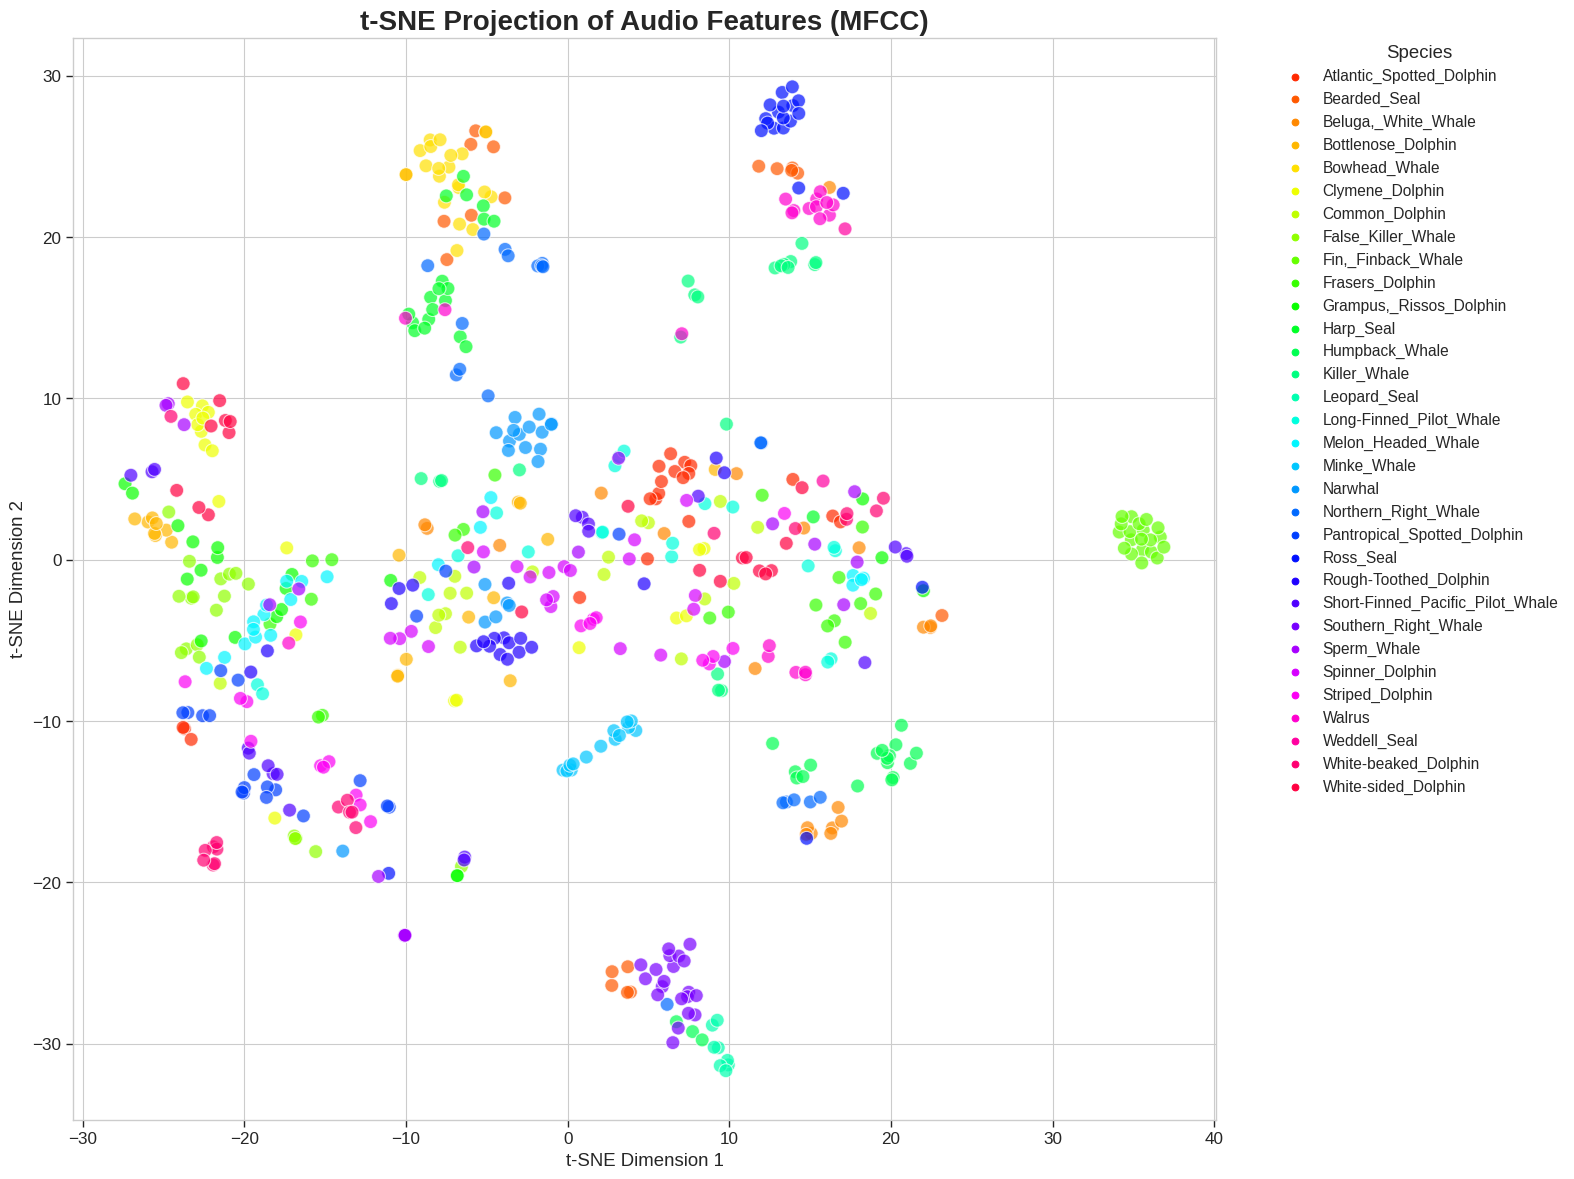

💡 Insight untuk Makalah: Jika titik-titik dengan warna sama berkumpul, berarti fitur akustik dapat membedakan spesies dengan baik.


In [60]:
# --- CELL 4: t-SNE CLUSTERING (The Winning Visual) ---
# Tujuan: Membuktikan apakah data ini "bisa dipisahkan" (separable) secara matematis.
# Jika titik-titik berkumpul sesuai warna, berarti fitur audio bagus & model punya harapan tinggi.

def extract_features(file_path):
    # Ekstrak MFCC (Mel-frequency cepstral coefficients) - fitur standar audio
    y, sr = librosa.load(file_path, duration=5, sr=32000) 
    # Pad jika kurang dari 5 detik
    if len(y) < 32000 * 5:
        y = np.pad(y, (0, 32000*5 - len(y)))
    else:
        y = y[:32000*5]
        
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
    return np.mean(mfcc.T, axis=0) # Ambil rata-rata MFCC

# Ambil sampel data (jangan semua kalau terlalu berat, misal 500 sampel)
# Untuk hasil terbaik di makalah, gunakan sebanyak mungkin
sample_df = df_meta.groupby('label').apply(lambda x: x.sample(min(len(x), 20))).reset_index(drop=True)

print("⏳ Mengekstrak fitur untuk t-SNE Clustering (Ini mungkin memakan waktu)...")
features = []
labels = []

for _, row in tqdm(sample_df.iterrows(), total=len(sample_df)):
    try:
        feat = extract_features(row['path'])
        features.append(feat)
        labels.append(row['label'])
    except:
        pass

# Normalisasi & t-SNE
X = np.array(features)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_scaled)

# Plotting
plt.figure(figsize=(16, 12))
sns.scatterplot(
    x=X_tsne[:,0], y=X_tsne[:,1],
    hue=labels,
    palette=sns.color_palette("hsv", len(set(labels))),
    legend="full",
    s=100,
    alpha=0.7
)
plt.title("t-SNE Projection of Audio Features (MFCC)", fontsize=20, fontweight='bold')
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0., fontsize='small', title='Species')
plt.tight_layout()
plt.show()

print("💡 Insight untuk Makalah: Jika titik-titik dengan warna sama berkumpul, berarti fitur akustik dapat membedakan spesies dengan baik.")

In [61]:
# --- UPDATE CELL DATA GATHERING ---
data = []
for label in sorted(os.listdir(TRAIN_DIR)):
    label_dir = os.path.join(TRAIN_DIR, label)
    if os.path.isdir(label_dir):
        for f in os.listdir(label_dir):
            if f.endswith('.wav'):
                # CONTOH: train-00000-of-00003_116.wav
                # KITA AMBIL: train-00000-of-00003 (sebagai Group ID)
                
                # Logika: Split berdasarkan underscore '_' terakhir
                group_id = f.rsplit('_', 1)[0] 
                
                data.append({
                    'filename': f,
                    'label': label,
                    'path': os.path.join(label_dir, f),
                    'group_id': group_id  # <--- KOLOM PENTING INI
                })

df_meta = pd.DataFrame(data)

# Cek hasilnya
print(f"Total File Audio: {len(df_meta)}")
print(f"Total Sumber Rekaman Unik (Group ID): {df_meta['group_id'].nunique()}")
print("\nContoh Data:")
display(df_meta[['filename', 'label', 'group_id']].head())

Total File Audio: 1357
Total Sumber Rekaman Unik (Group ID): 3

Contoh Data:


,filename,label,group_id
0,train-00001-of-00003_293.wav,Atlantic_Spotted_Dolphin,train-00001-of-00003
1,train-00000-of-00003_99.wav,Atlantic_Spotted_Dolphin,train-00000-of-00003
2,train-00000-of-00003_8.wav,Atlantic_Spotted_Dolphin,train-00000-of-00003
3,train-00000-of-00003_435.wav,Atlantic_Spotted_Dolphin,train-00000-of-00003
4,train-00002-of-00003_198.wav,Atlantic_Spotted_Dolphin,train-00002-of-00003


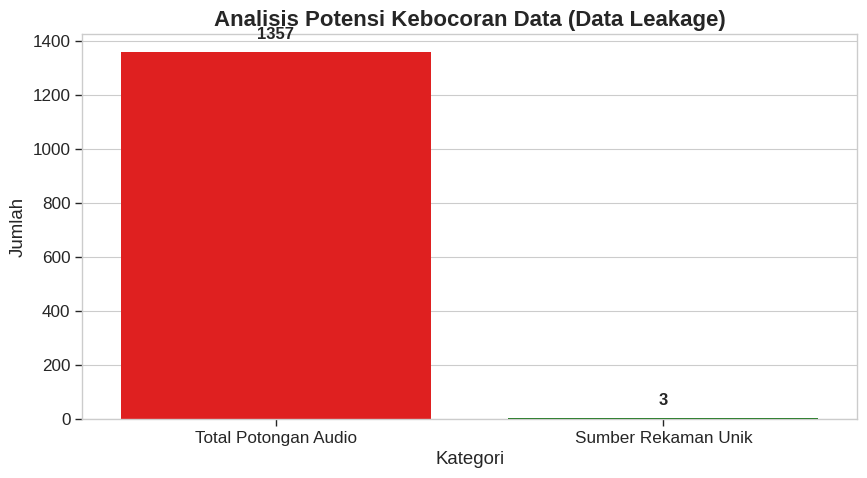

Rata-rata: 1 Rekaman dipotong menjadi 452.3 file audio.
KESIMPULAN: Wajib menggunakan GroupKFold untuk validasi.


In [62]:
# --- VISUALISASI DATA LEAKAGE ---
plt.figure(figsize=(10, 5))
leakage_stats = pd.DataFrame({
    'Kategori': ['Total Potongan Audio', 'Sumber Rekaman Unik'],
    'Jumlah': [len(df_meta), df_meta['group_id'].nunique()]
})

sns.barplot(x='Kategori', y='Jumlah', data=leakage_stats, palette=['red', 'green'])
plt.title("Analisis Potensi Kebocoran Data (Data Leakage)", fontsize=16, fontweight='bold')
plt.ylabel("Jumlah")

# Tambahkan angka di atas bar
for i, v in enumerate(leakage_stats['Jumlah']):
    plt.text(i, v + 50, str(v), ha='center', fontweight='bold', fontsize=12)

plt.show()

# Hitung rata-rata potongan per rekaman
avg_clips = len(df_meta) / df_meta['group_id'].nunique()
print(f"Rata-rata: 1 Rekaman dipotong menjadi {avg_clips:.1f} file audio.")
print("KESIMPULAN: Wajib menggunakan GroupKFold untuk validasi.")

# MODELLING

In [63]:
# Install library model canggih
!pip install timm -q

import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import torchaudio
import torchaudio.transforms as T
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, classification_report
import timm # Library untuk model-model terbaru (EfficientNet/ConvNeXt)
from tqdm.notebook import tqdm
import warnings

warnings.filterwarnings('ignore')

# --- CONFIGURATION ---
CFG = {
    'root_dir': '/kaggle/input/intelecta-final-dataset/dataset_siap_pakai/dataset_siap_pakai',
    'sample_rate': 32000,   # Standarisasi SR sesuai temuan EDA
    'duration': 5,          # Target durasi
    'n_mels': 128,          # Resolusi frekuensi (Y-axis)
    'n_fft': 2048,
    'hop_length': 512,
    'image_size': 224,      # Input size standar CNN
    'batch_size': 32,
    'epochs': 30,           # Epoch per model
    'lr': 1e-3,
    'n_folds': 5,
    'seed': 42,
    'device': 'cuda' if torch.cuda.is_available() else 'cpu'
}

def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(CFG['seed'])
print(f"✅ Setup Ready on {CFG['device']}")

✅ Setup Ready on cuda


In [64]:
# 1. Load Metadata
data = []
train_dir = os.path.join(CFG['root_dir'], 'train')

for label in sorted(os.listdir(train_dir)):
    label_dir = os.path.join(train_dir, label)
    if os.path.isdir(label_dir):
        for f in os.listdir(label_dir):
            if f.endswith('.wav'):
                # INSIGHT EDA: Cegah Data Leakage dengan Group ID
                # Format: train-00000-of-00003_116.wav -> Group: train-00000-of-00003
                group_id = f.rsplit('_', 1)[0]
                data.append({
                    'filename': f,
                    'label': label,
                    'path': os.path.join(label_dir, f),
                    'group_id': group_id
                })

df = pd.DataFrame(data)

# 2. Mapping Labels
classes = sorted(df['label'].unique())
label2id = {k: v for v, k in enumerate(classes)}
id2label = {v: k for k, v in label2id.items()}
df['label_id'] = df['label'].map(label2id)

# 3. Stratified Group K-Fold (Solusi Leakage)
sgkf = StratifiedGroupKFold(n_splits=CFG['n_folds'], shuffle=True, random_state=CFG['seed'])
df['fold'] = -1
for fold, (train_idx, val_idx) in enumerate(sgkf.split(df, df['label_id'], df['group_id'])):
    df.loc[val_idx, 'fold'] = fold

# 4. Class Weights (Solusi Imbalance)
# Kita hitung bobot invers agar model fokus ke kelas minoritas
class_counts = df['label_id'].value_counts().sort_index()
weights = 1.0 / class_counts
weights = weights / weights.sum() * len(classes) # Normalize
class_weights = torch.tensor(weights.values, dtype=torch.float).to(CFG['device'])

print(f"Data Loaded: {len(df)} samples.")
print(f"Unique Groups (Sources): {df['group_id'].nunique()}")
print("✅ Stratified Group K-Fold Applied.")
print("✅ Class Weights Calculated.")

Data Loaded: 1357 samples.
Unique Groups (Sources): 3
✅ Stratified Group K-Fold Applied.
✅ Class Weights Calculated.


In [65]:
class AdvancedAudioDataset(Dataset):
    def __init__(self, df, transform=None, is_train=False):
        self.df = df
        self.is_train = is_train
        
        # Spectrogram Config
        self.mel_spec = T.MelSpectrogram(
            sample_rate=CFG['sample_rate'],
            n_fft=CFG['n_fft'],
            hop_length=CFG['hop_length'],
            n_mels=CFG['n_mels'],
            f_min=20, # Filter low freq noise
            f_max=16000
        )
        # INSIGHT EDA: Gunakan dB scale untuk mengangkat sinyal lemah
        self.to_db = T.AmplitudeToDB()
        
        # Augmentasi (Hanya untuk Train)
        self.spec_aug = torch.nn.Sequential(
            T.FrequencyMasking(freq_mask_param=15),
            T.TimeMasking(time_mask_param=35)
        )

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        waveform, sr = torchaudio.load(row['path'])
        
        # 1. Resample (Standarisasi Input)
        if sr != CFG['sample_rate']:
            waveform = T.Resample(sr, CFG['sample_rate'])(waveform)
            
        # 2. Fix Duration Strategy (INSIGHT EDA: Banyak file pendek)
        # Kita gunakan "Tile/Loop Padding" alih-alih Zero Padding
        target_len = CFG['sample_rate'] * CFG['duration']
        current_len = waveform.shape[1]
        
        if current_len < target_len:
            # Loop audio sampai memenuhi target length
            # Ini membuat fitur visual lebih padat dibanding isi 0 (hitam)
            repeat_times = (target_len // current_len) + 1
            waveform = waveform.repeat(1, repeat_times)
            waveform = waveform[:, :target_len]
        elif current_len > target_len:
            # Random Crop untuk Training, Center Crop untuk Validasi
            if self.is_train:
                start = torch.randint(0, current_len - target_len, (1,)).item()
            else:
                start = (current_len - target_len) // 2
            waveform = waveform[:, start:start+target_len]

        # 3. Generate Image (Spectrogram)
        spec = self.mel_spec(waveform)
        spec = self.to_db(spec) # Log Scale
        
        # 4. Augmentation
        if self.is_train:
            spec = self.spec_aug(spec)

        # 5. Image Processing
        # Resize ke 224x224
        spec = torch.nn.functional.interpolate(
            spec.unsqueeze(0), 
            size=(CFG['image_size'], CFG['image_size']), 
            mode='bilinear', align_corners=False
        ).squeeze(0)
        
        # INSIGHT EDA: Min-Max Scaling per Image
        # Agar sinyal pelan tetap punya kontras tinggi (0 sampai 1)
        spec = (spec - spec.min()) / (spec.max() - spec.min() + 1e-6)
        
        # Expand to 3 Channels (RGB-like for Transfer Learning)
        spec = spec.expand(3, -1, -1)

        return spec, torch.tensor(row['label_id'], dtype=torch.long)

In [ ]:
class AudioClassifier(nn.Module):
    def __init__(self, model_name, num_classes, pretrained=True):
        super().__init__()
        # Menggunakan library TIMM untuk akses ribuan model SOTA
        self.model = timm.create_model(model_name, pretrained=pretrained, num_classes=num_classes)

    def forward(self, x):
        return self.model(x)

def get_model(model_name):
    model = AudioClassifier(model_name, len(classes))
    return model.to(CFG['device'])

# List Model yang akan diuji
models_to_test = [
    'resnet34',          # Baseline kuat
    ' efficientnet_b0',  # Ringan & Akurat
    'convnext_tiny'      # Modern Architecture (Sering menang di ImageNet)
]

In [66]:
def train_and_evaluate(model_name, fold_id=0):
    print(f"\n{'='*20} TRAINING MODEL: {model_name} {'='*20}")
    
    # Setup Data
    train_df = df[df['fold'] != fold_id].reset_index(drop=True)
    val_df = df[df['fold'] == fold_id].reset_index(drop=True)
    
    train_ds = AdvancedAudioDataset(train_df, is_train=True)
    val_ds = AdvancedAudioDataset(val_df, is_train=False)
    
    train_loader = DataLoader(train_ds, batch_size=CFG['batch_size'], shuffle=True, num_workers=2)
    val_loader = DataLoader(val_ds, batch_size=CFG['batch_size'], shuffle=False, num_workers=2)
    
    # Setup Model & Training
    model = get_model(model_name)
    optimizer = optim.AdamW(model.parameters(), lr=CFG['lr'])
    criterion = nn.CrossEntropyLoss(weight=class_weights) # Weighted Loss
    scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=CFG['lr'], steps_per_epoch=len(train_loader), epochs=CFG['epochs'])
    
    best_f1 = 0.0
    
    for epoch in range(CFG['epochs']):
        model.train()
        train_loss = 0
        for spec, label in tqdm(train_loader, desc=f"Epoch {epoch+1}", leave=False):
            spec, label = spec.to(CFG['device']), label.to(CFG['device'])
            optimizer.zero_grad()
            output = model(spec)
            loss = criterion(output, label)
            loss.backward()
            optimizer.step()
            scheduler.step()
            train_loss += loss.item()
            
        # Validation
        model.eval()
        val_preds = []
        val_targets = []
        with torch.no_grad():
            for spec, label in val_loader:
                spec, label = spec.to(CFG['device']), label.to(CFG['device'])
                output = model(spec)
                preds = torch.argmax(output, dim=1)
                val_preds.extend(preds.cpu().numpy())
                val_targets.extend(label.cpu().numpy())
        
        val_f1 = f1_score(val_targets, val_preds, average='macro')
        
        if val_f1 > best_f1:
            best_f1 = val_f1
            # Simpan bobot model
            torch.save(model.state_dict(), f"best_model_{model_name}.pth")
            
        print(f"Ep {epoch+1} | Loss: {train_loss/len(train_loader):.4f} | Val F1: {val_f1:.4f} | Best: {best_f1:.4f}")
        
    return best_f1

# --- RUN COMPARISON ---
results = {}
for m in models_to_test:
    score = train_and_evaluate(m)
    results[m] = score

print("\n🏆 FINAL RESULTS COMPARISON 🏆")
best_model_name = max(results, key=results.get)
for m, s in results.items():
    print(f"{m}: {s:.4f}")

print(f"\nRecommendation: Gunakan model '{best_model_name}' untuk submission akhir!")


==================== TRAINING MODEL: resnet34 ====================


Epoch 1:   0%|          | 0/29 [00:00<?, ?it/s]

Ep 1 | Loss: 3.4609 | Val F1: 0.0203 | Best: 0.0203


Epoch 2:   0%|          | 0/29 [00:00<?, ?it/s]

Ep 2 | Loss: 3.4304 | Val F1: 0.0465 | Best: 0.0465


Epoch 3:   0%|          | 0/29 [00:00<?, ?it/s]

... (172 outputs left out)

Epoch 29:   0%|          | 0/29 [00:00<?, ?it/s]

Ep 29 | Loss: 0.0193 | Val F1: 0.8712 | Best: 0.8738


Epoch 30:   0%|          | 0/29 [00:00<?, ?it/s]

Ep 30 | Loss: 0.0226 | Val F1: 0.8695 | Best: 0.8738

🏆 FINAL RESULTS COMPARISON 🏆
resnet34: 0.9069
 efficientnet_b0: 0.8825
convnext_tiny: 0.8738

Recommendation: Gunakan model 'resnet34' untuk submission akhir!


In [68]:
# Load Model Pemenang
print(f"🚀 Generating Submission using {best_model_name}...")
final_model = get_model(best_model_name)
final_model.load_state_dict(torch.load(f"best_model_{best_model_name}.pth"))
final_model.eval()

# Setup Test Data
class TestDataset(Dataset):
    def __init__(self, file_paths):
        self.file_paths = file_paths
        # Config sama persis dengan validation (tanpa augmentasi)
        self.mel_spec = T.MelSpectrogram(sample_rate=CFG['sample_rate'], n_fft=2048, hop_length=512, n_mels=128, f_min=20, f_max=16000)
        self.to_db = T.AmplitudeToDB()

    def __len__(self): return len(self.file_paths)

    def __getitem__(self, idx):
        path = self.file_paths[idx]
        filename = os.path.basename(path)
        waveform, sr = torchaudio.load(path)
        if sr != CFG['sample_rate']: waveform = T.Resample(sr, CFG['sample_rate'])(waveform)
        
        # Loop Padding untuk Test
        target_len = CFG['sample_rate'] * CFG['duration']
        current_len = waveform.shape[1]
        if current_len < target_len:
            repeat = (target_len // current_len) + 1
            waveform = waveform.repeat(1, repeat)
            waveform = waveform[:, :target_len]
        else:
            # Center Crop untuk Test (Ambil tengah)
            start = (current_len - target_len) // 2
            waveform = waveform[:, start:start+target_len]

        spec = self.mel_spec(waveform)
        spec = self.to_db(spec)
        spec = torch.nn.functional.interpolate(spec.unsqueeze(0), size=(224, 224), mode='bilinear', align_corners=False).squeeze(0)
        spec = (spec - spec.min()) / (spec.max() - spec.min() + 1e-6)
        spec = spec.expand(3, -1, -1)
        return spec, filename

test_folder = os.path.join(CFG['root_dir'], 'test')
test_files = [os.path.join(test_folder, f) for f in os.listdir(test_folder) if f.endswith('.wav')]
test_ds = TestDataset(test_files)
test_loader = DataLoader(test_ds, batch_size=CFG['batch_size'], shuffle=False, num_workers=2)

# Prediction Loop
all_preds = []
all_files = []

with torch.no_grad():
    for spec, fnames in tqdm(test_loader):
        spec = spec.to(CFG['device'])
        outputs = final_model(spec)
        preds = torch.argmax(outputs, dim=1)
        
        all_preds.extend(preds.cpu().numpy())
        all_files.extend(fnames)

# Create CSV
sub = pd.DataFrame({'audio': all_files, 'species': [id2label[p] for p in all_preds]})
sub.to_csv('submission_advanced.csv', index=False)
print("✅ Submission Ready: submission_advanced.csv")

🚀 Generating Submission using resnet34...


  0%|          | 0/11 [00:00<?, ?it/s]

✅ Submission Ready: submission_advanced.csv
